# 🧠📈 Human Personality Analysis & Classification¶
_ By Mostafa Saad

## 📚 Importing Required Libraries


In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import cross_val_score


## 🔧 Data Preparation

### 📂 Load Dataset


In [2]:
df=pd.read_csv('/kaggle/input/extrovert-vs-introvert-behavior-data/personality_dataset.csv')

### 🔍 Dataset Overview

In [3]:
df.head()

,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,4.0,No,4.0,6.0,No,13.0,5.0,Extrovert
1,9.0,Yes,0.0,0.0,Yes,0.0,3.0,Introvert
2,9.0,Yes,1.0,2.0,Yes,5.0,2.0,Introvert
3,0.0,No,6.0,7.0,No,14.0,8.0,Extrovert
4,3.0,No,9.0,4.0,No,8.0,5.0,Extrovert


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2900 entries, 0 to 2899
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Time_spent_Alone           2837 non-null   float64
 1   Stage_fear                 2827 non-null   object 
 2   Social_event_attendance    2838 non-null   float64
 3   Going_outside              2834 non-null   float64
 4   Drained_after_socializing  2848 non-null   object 
 5   Friends_circle_size        2823 non-null   float64
 6   Post_frequency             2835 non-null   float64
 7   Personality                2900 non-null   object 
dtypes: float64(5), object(3)
memory usage: 181.4+ KB


In [5]:
print('Descirbe nomercal data :')
df.describe()


Descirbe nomercal data :


,Time_spent_Alone,Social_event_attendance,Going_outside,Friends_circle_size,Post_frequency
count,2837.000000,2838.000000,2834.000000,2823.000000,2835.000000
mean,4.505816,3.963354,3.000000,6.268863,3.564727
std,3.479192,2.903827,2.247327,4.289693,2.926582
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,2.000000,1.000000,3.000000,1.000000
50%,4.000000,3.000000,3.000000,5.000000,3.000000
75%,8.000000,6.000000,5.000000,10.000000,6.000000
max,11.000000,10.000000,7.000000,15.000000,10.000000


In [6]:
print('Descirbe non nomercal data :')
df.describe(include='object')

Descirbe non nomercal data :


,Stage_fear,Drained_after_socializing,Personality
count,2827,2848,2900
unique,2,2,2
top,No,No,Extrovert
freq,1417,1441,1491


In [7]:
def missing_summary(df):
    missing = df.isnull().sum()
    missing_percent = 100 * missing / len(df)
    result = pd.DataFrame({
        'Missing Values': missing,
        'Percent (%)': missing_percent
    })
    result = result[result['Missing Values'] > 0]
    return result.sort_values('Percent (%)', ascending=False)

# Display the missing values table
display(missing_summary(df).style.format({'Percent (%)': '{:.1f}%'}))

,Missing Values,Percent (%)
Friends_circle_size,77,2.7%
Stage_fear,73,2.5%
Going_outside,66,2.3%
Post_frequency,65,2.2%
Time_spent_Alone,63,2.2%
Social_event_attendance,62,2.1%
Drained_after_socializing,52,1.8%


## 📊 Data Visualization

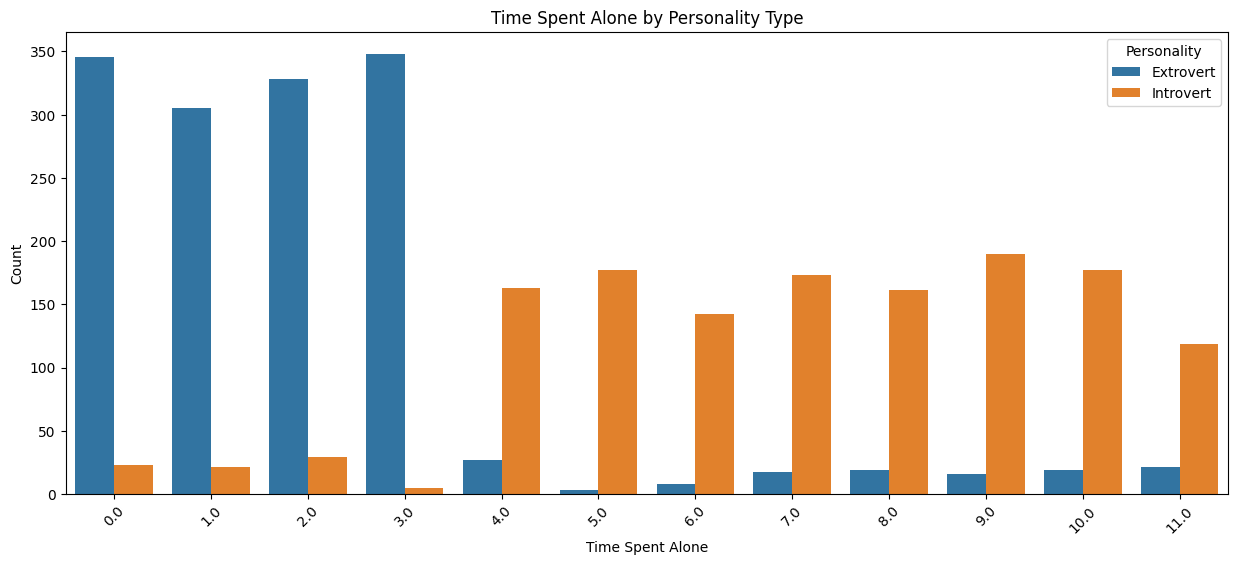

In [8]:
plt.figure(figsize=(15, 6))
sns.countplot(data=df, x='Time_spent_Alone', hue='Personality')
plt.title("Time Spent Alone by Personality Type")
plt.xlabel("Time Spent Alone")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()


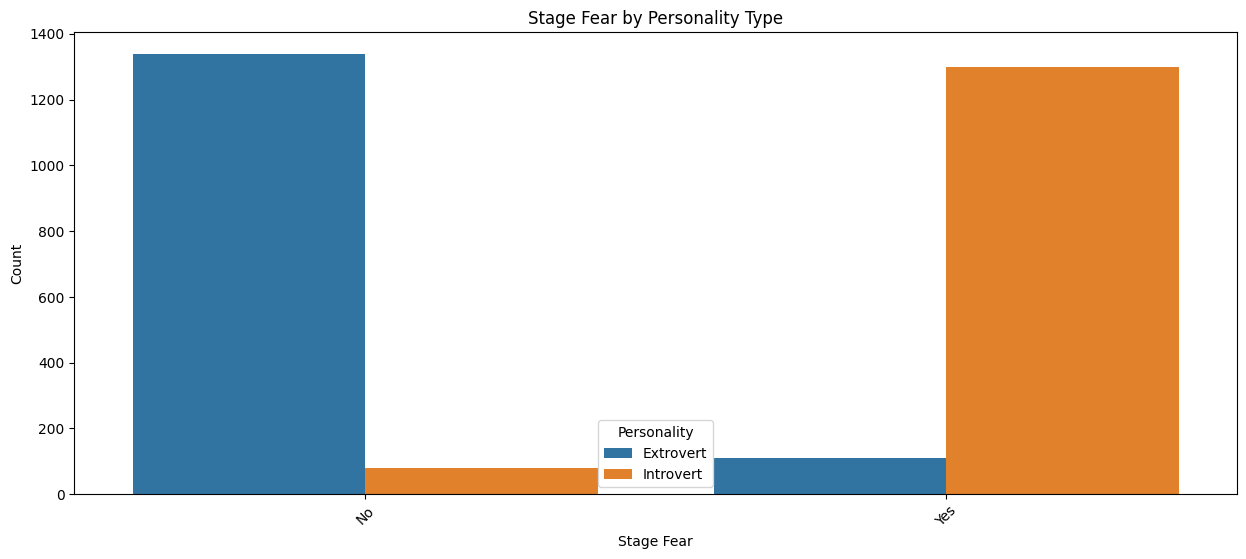

In [9]:
plt.figure(figsize=(15, 6))
sns.countplot(data=df, x='Stage_fear',hue='Personality')
plt.title("Stage Fear by Personality Type")
plt.xlabel("Stage Fear")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

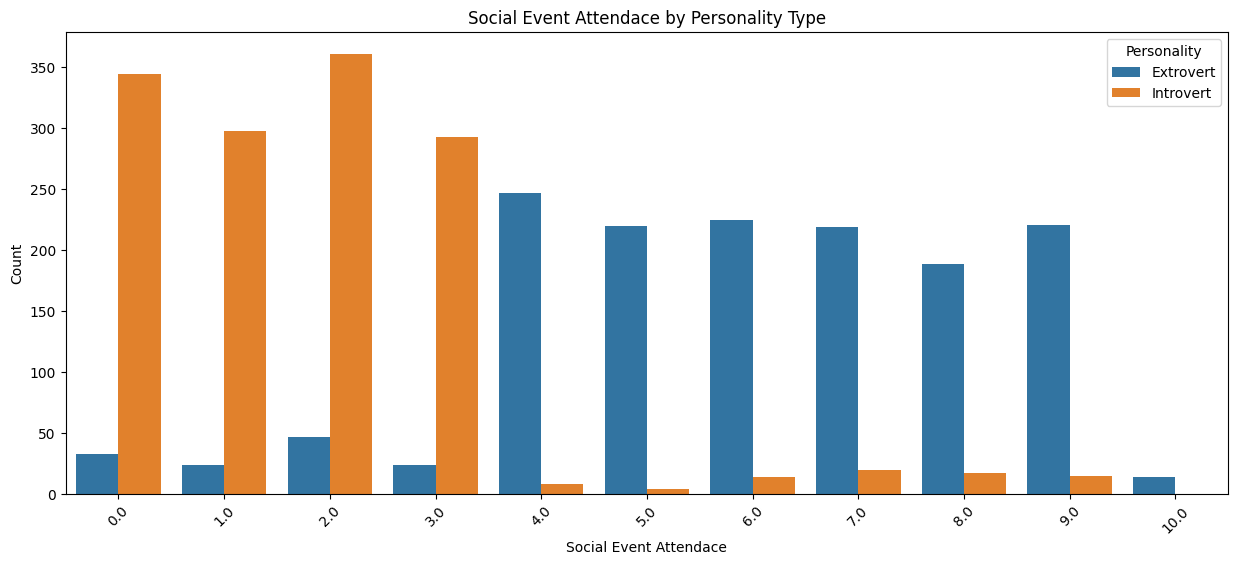

In [10]:
plt.figure(figsize=(15, 6))
sns.countplot(data=df, x='Social_event_attendance',hue='Personality')
plt.title("Social Event Attendace by Personality Type")
plt.xlabel("Social Event Attendace")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

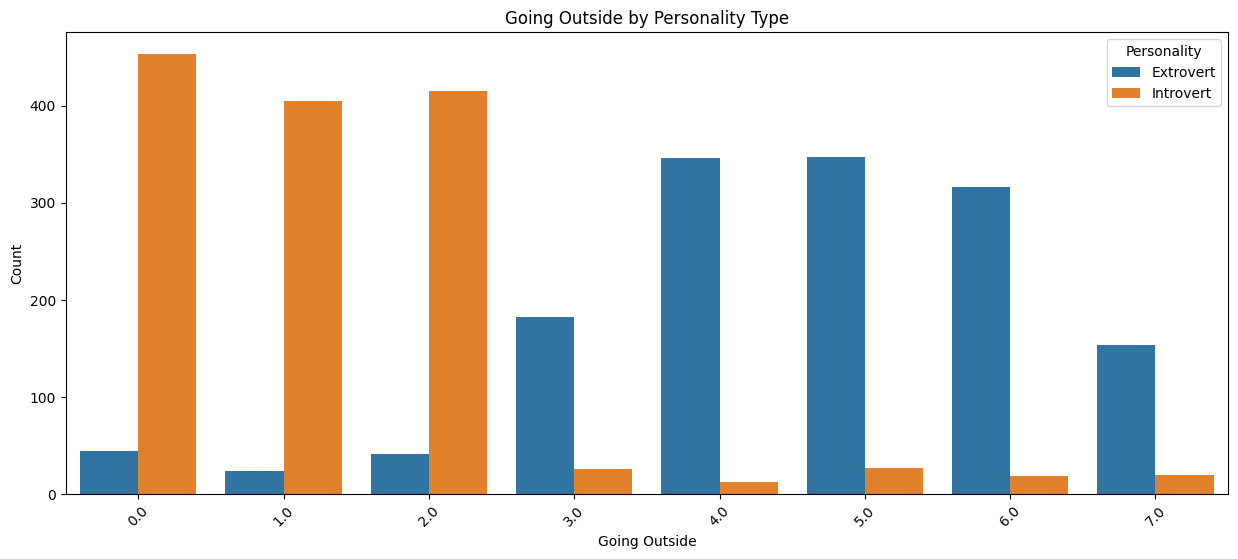

In [11]:
plt.figure(figsize=(15, 6))
sns.countplot(data=df, x='Going_outside',hue='Personality')
plt.title("Going Outside by Personality Type")
plt.xlabel("Going Outside")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

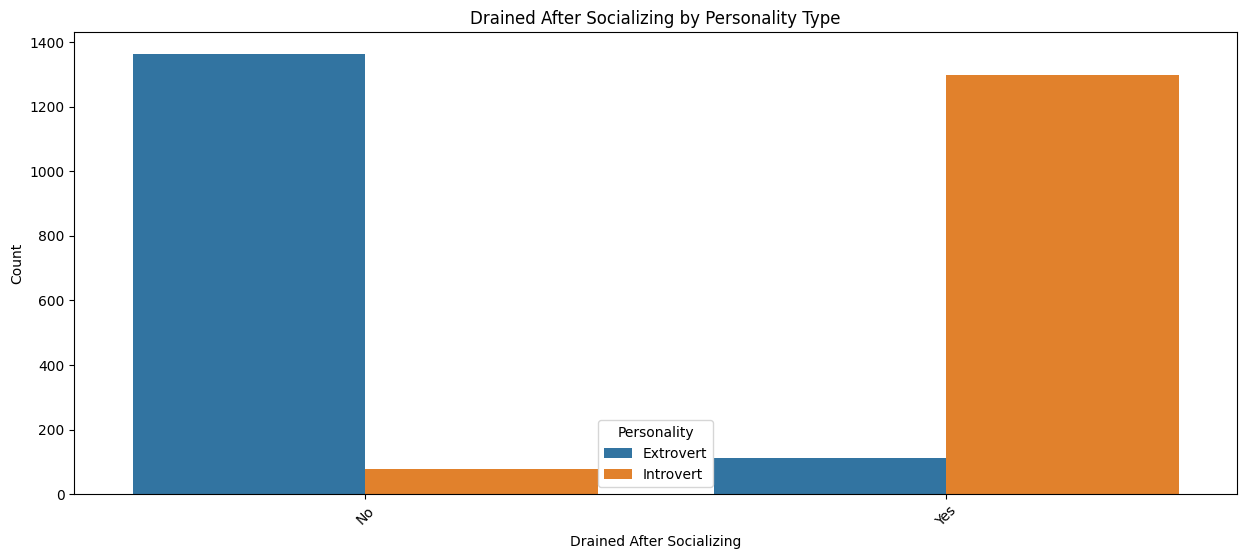

In [12]:
plt.figure(figsize=(15, 6))
sns.countplot(data=df, x='Drained_after_socializing',hue='Personality')
plt.title("Drained After Socializing by Personality Type")
plt.xlabel("Drained After Socializing")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

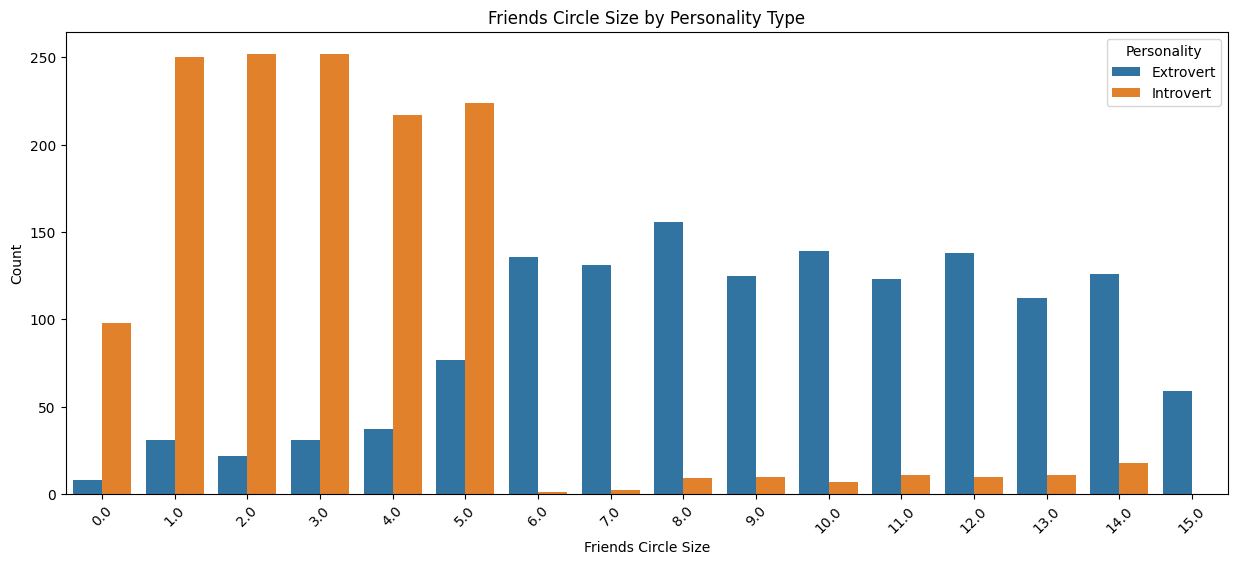

In [13]:
plt.figure(figsize=(15, 6))
sns.countplot(data=df, x='Friends_circle_size',hue='Personality')
plt.title("Friends Circle Size by Personality Type")
plt.xlabel("Friends Circle Size")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

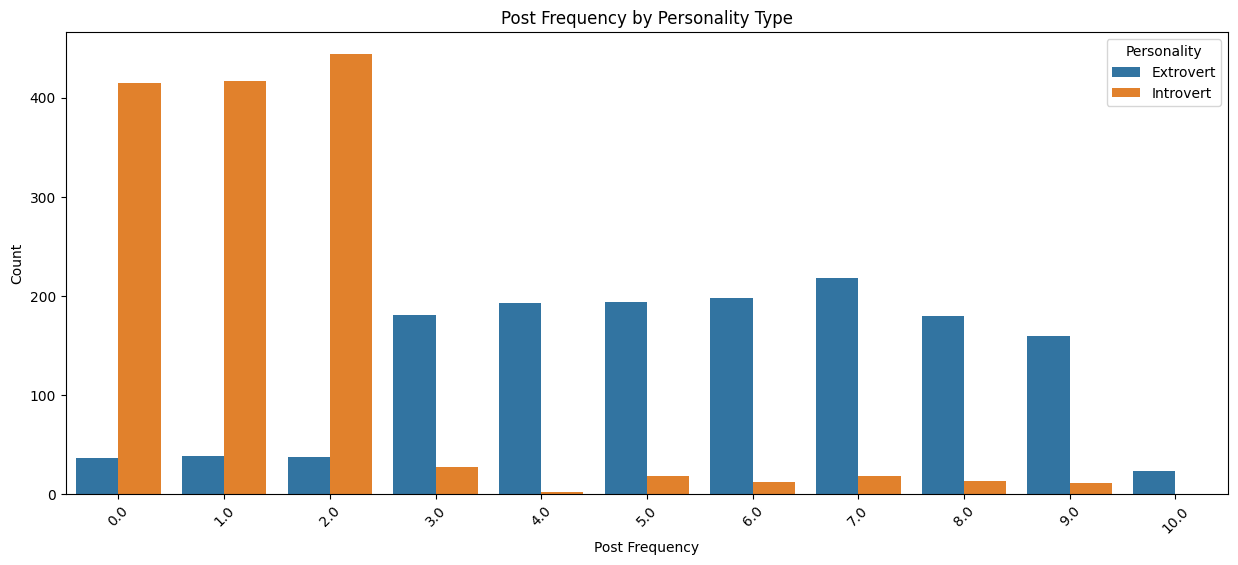

In [14]:
plt.figure(figsize=(15, 6))
sns.countplot(data=df, x='Post_frequency',hue='Personality')
plt.title("Post Frequency by Personality Type")
plt.xlabel("Post Frequency")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

## ⚙️ Preparing Data for Machine Learning

### 🧠 Encoding Categorical Features with LabelEncoder

In [15]:
# Make a copy to avoid changing original
df_encoded = df.copy()

# Create LabelEncoder
le = LabelEncoder()

# Apply LabelEncoder to all object (categorical) columns
for col in df_encoded.columns:
    if df_encoded[col].dtype == 'object':
        df_encoded[col] = le.fit_transform(df_encoded[col])

### 🔥 Visualizing Feature Relationships with a Correlation Matrix Heatmap


Text(0.5, 1.0, 'Correlation Matrix Heatmap')

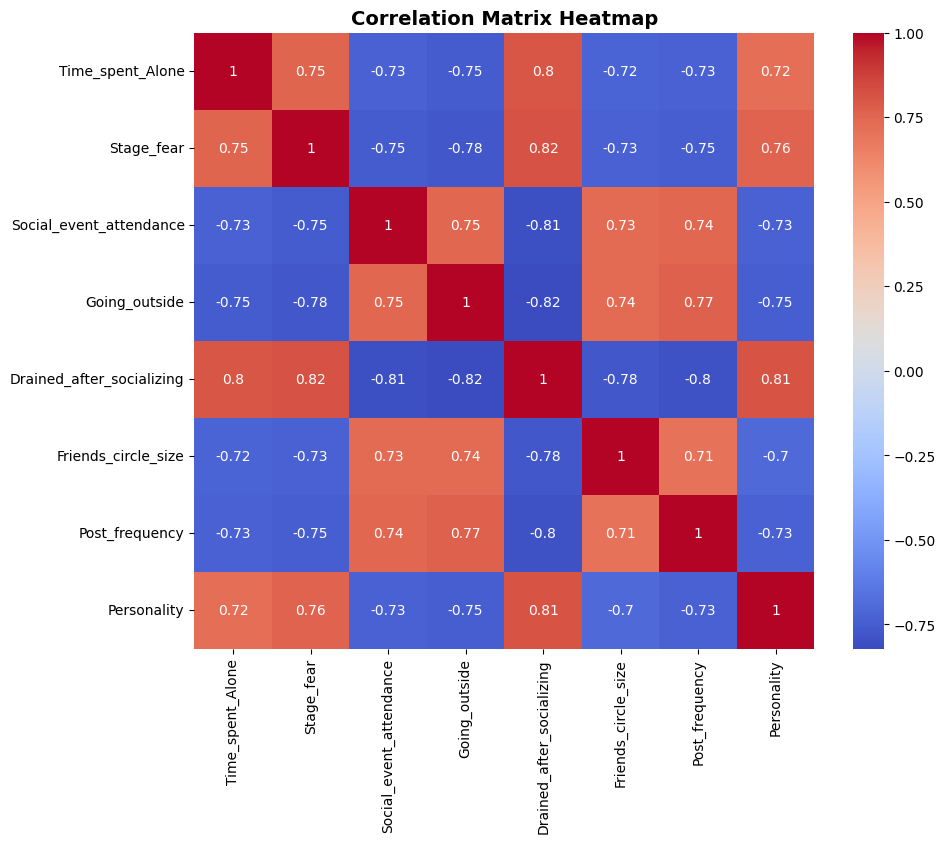

In [16]:
correlation_matrix=df_encoded.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix,cmap='coolwarm',annot=True)
plt.title("Correlation Matrix Heatmap", fontsize=14, fontweight='bold')


### 🧹 Handling Missing Values with Mean Imputation


In [17]:

# Handle missing values in X_train
imputer = SimpleImputer(strategy='mean')
df_imputer = imputer.fit_transform(df_encoded)
df_imputer = pd.DataFrame(df_imputer, columns=df.columns)

### 🧪 Splitting Data into Training and Testing Sets


In [18]:
y=df_imputer['Personality']
X = df_imputer.drop('Personality', axis=1)
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.3 ,random_state=44)

## 🤖 Model Training & Evaluation

### 🔍 Model Comparison with Hyperparameter Tuning


In [19]:
# Define models and hyperparameter grids
models = {
    'logistic': {
        'model': LogisticRegression(max_iter=1000),
        'use_scaled': False,
        'params': {
            'C': np.logspace(-4, 4, 20),
            'solver': ['lbfgs', 'liblinear']
        }
    },
    'svm': {
        'model': SVC(probability=True),
        'use_scaled': False,
        'params': {
            'C': np.logspace(-3, 3, 20),
            'kernel': ['rbf', 'linear'],
            'gamma': ['scale', 'auto', 0.1, 1]
        }
    },
    'rf': {
        'model': RandomForestClassifier(random_state=42),
        'use_scaled': False,
        'params': {
            'n_estimators': [100, 150],
            'max_depth': [None, 10],
            'min_samples_split': [2, 5]
        }
    },
    'gb': {
        'model': GradientBoostingClassifier(random_state=42),
        'use_scaled': False,
        'params': {
            'n_estimators': [100, 200, 300],
            'learning_rate': [0.01, 0.1, 0.2],
            'max_depth': [3, 5, 7]
        }
    },
    'knn': {
        'model': KNeighborsClassifier(),
        'use_scaled': False,
        'params': {
            'n_neighbors': [3, 5, 7, 9],
            'weights': ['uniform', 'distance']
        }
    },
    'dt': {
        'model': DecisionTreeClassifier(random_state=42),
        'use_scaled': False,
        'params': {
            'max_depth': [None, 5, 10, 15],
            'min_samples_split': [2, 5, 10]
        }
    },
    'xgb': {
        'model': XGBClassifier(random_state=42, eval_metric='logloss'),
        'use_scaled': False,
        'params': {
            'n_estimators': [100, 150],
            'learning_rate': [0.05, 0.1],
            'max_depth': [3, 5],
            'subsample': [0.8]
        }
    }
}

# Assume X_train and y_train already defined
results = []

for model_name, mp in models.items():
    print(f"Training {model_name.upper()}...")

    clf = RandomizedSearchCV(
        estimator=mp['model'],
        param_distributions=mp['params'],
        n_iter=20,
        cv=3,
        scoring='f1_weighted',
        n_jobs=-1,
        random_state=42
    )

    clf.fit(X_train, y_train)

    results.append({
        'model': model_name,
        'best_score': clf.best_score_,
        'best_params': clf.best_params_
    })

# Show results

df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by="best_score", ascending=False)

print("\n📊 Model Performance (Cross-Validation F1-Weighted Scores):")
print(df_results)

Training LOGISTIC...
Training SVM...
Training RF...


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:305: UserWarning: The total space of parameters 8 is smaller than n_iter=20. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Training GB...
Training KNN...


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:305: UserWarning: The total space of parameters 8 is smaller than n_iter=20. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Training DT...
Training XGB...


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:305: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:305: UserWarning: The total space of parameters 8 is smaller than n_iter=20. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(



📊 Model Performance (Cross-Validation F1-Weighted Scores):
      model  best_score                                        best_params
4       knn    0.939394           {'weights': 'uniform', 'n_neighbors': 7}
0  logistic    0.938903    {'solver': 'lbfgs', 'C': 0.0006951927961775605}
1       svm    0.938903  {'kernel': 'linear', 'gamma': 0.1, 'C': 0.0088...
3        gb    0.938903  {'n_estimators': 100, 'max_depth': 3, 'learnin...
6       xgb    0.938409  {'subsample': 0.8, 'n_estimators': 100, 'max_d...
2        rf    0.937422  {'n_estimators': 100, 'min_samples_split': 5, ...
5        dt    0.935949           {'min_samples_split': 2, 'max_depth': 5}


### 🔀 Stacking Classifier: Final Model Ensemble


✅ Stacking Model F1-Weighted Score: 0.9389 ± 0.0119

📄 Classification Report:
              precision    recall  f1-score   support

         0.0       0.94      0.92      0.93       479
         1.0       0.90      0.93      0.92       391

    accuracy                           0.92       870
   macro avg       0.92      0.92      0.92       870
weighted avg       0.92      0.92      0.92       870



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128204 (\N{PUSHPIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


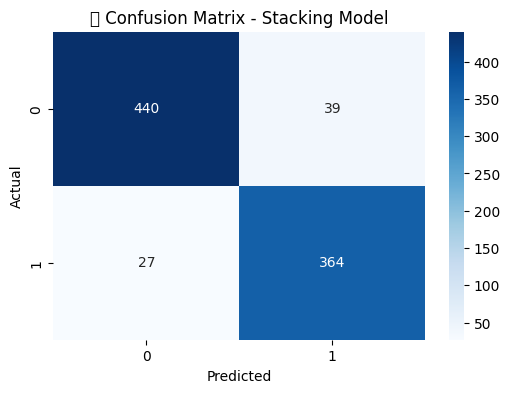

In [20]:
estimators = [
    ('knn', KNeighborsClassifier(**df_results.loc[df_results['model'] == 'knn']['best_params'].iloc[0])),
    ('logistic', LogisticRegression(**df_results.loc[df_results['model'] == 'logistic']['best_params'].iloc[0], max_iter=1000)),
    ('svm', SVC(**df_results.loc[df_results['model'] == 'svm']['best_params'].iloc[0], probability=True)),
    ('gb', GradientBoostingClassifier(**df_results.loc[df_results['model'] == 'gb']['best_params'].iloc[0], random_state=42)),
    ('xgb', XGBClassifier(**df_results.loc[df_results['model'] == 'xgb']['best_params'].iloc[0], random_state=42, eval_metric='logloss'))
]
stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=1000),
    n_jobs=-1
)
stacking_clf.fit(X_train, y_train)
stacking_scores = cross_val_score(
    stacking_clf, X_train, y_train,
    cv=3, scoring='f1_weighted', n_jobs=-1
)

print(f"\n✅ Stacking Model F1-Weighted Score: {stacking_scores.mean():.4f} ± {stacking_scores.std():.4f}")
y_pred = stacking_clf.predict(X_test)

print("\n📄 Classification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("📌 Confusion Matrix - Stacking Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### 🔍 Analyzing Feature Importance Using Random Forest Classifier



Feature Importance (Random Forest):
                     Feature  Importance
4  Drained_after_socializing    0.260649
1                 Stage_fear    0.222031
2    Social_event_attendance    0.151925
6             Post_frequency    0.139082
3              Going_outside    0.104720
0           Time_spent_Alone    0.097148
5        Friends_circle_size    0.024444


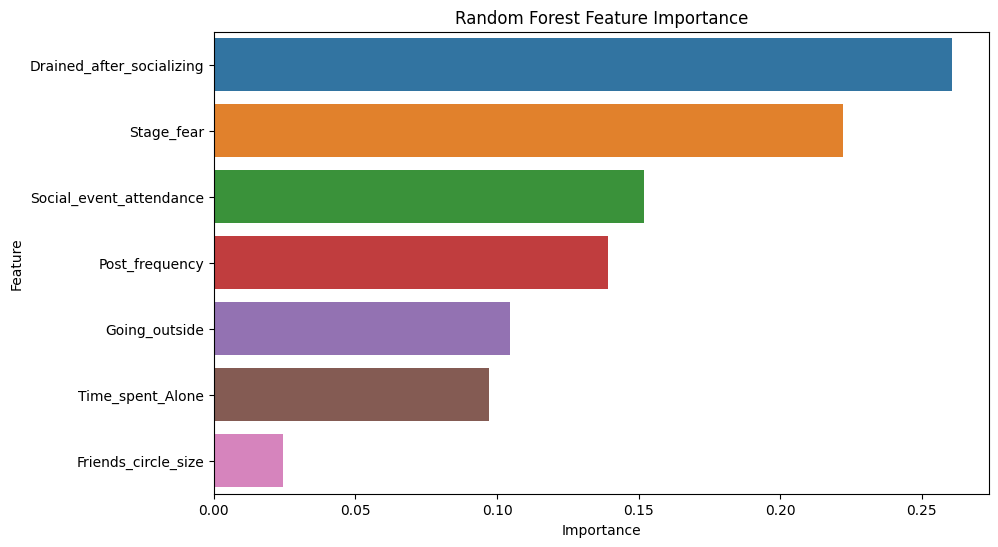

In [21]:
# Random Forest feature importance
rf_model = RandomForestClassifier(**df_results.loc[df_results['model'] == 'rf']['best_params'].iloc[0], random_state=42)
rf_model.fit(X_train, y_train)
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)
feature_importance.to_csv('/kaggle/working/feature_importance.csv', index=False)
print("\nFeature Importance (Random Forest):")
print(feature_importance)

# Feature importance bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance)
plt.title('Random Forest Feature Importance')
plt.savefig('/kaggle/working/feature_importance_plot.png')
plt.show()

##  ✅ Conclusion & Analysis
### 🔍 1. Exploratory Data Analysis (EDA)
📊 Numerical Features Overview:
Time Spent Alone: Average of 4.5 hours, with a wide variation (std = 3.47), suggesting diverse personal solitude habits.

Social Event Attendance and Going Outside: Averaging around 4 and 3 times respectively, indicating a moderate level of social engagement.

Post Frequency: Mean of ~3.5, reflecting average online activity.

Friends Circle Size: Median of 5, with some having very limited or larger networks.

🧾 Categorical Features:
Stage Fear: Most participants reported "No", meaning many are confident in public settings.

Drained After Socializing: A majority answered "Yes", suggesting introverted tendencies.

Personality Label: The target class was well distributed, with Extroverts being slightly more frequent.

### 🧠 2. Model Performance Overview
Model	F1-Score (Weighted)	Best Parameters
KNN	0.939	n_neighbors=7, weights='uniform'
Logistic Regression	0.938	C≈0.0007, solver='lbfgs'
SVM	0.938	kernel='linear', C≈0.0088, gamma=0.1
Gradient Boosting	0.938	n_estimators=100, max_depth=3
XGBoost	0.938	subsample=0.8, n_estimators=100
Random Forest	0.937	n_estimators=100, min_samples_split=5
Decision Tree	0.935	max_depth=5, min_samples_split=2
✅ Best Performing Model: K-Nearest Neighbors (KNN) achieved the highest F1-Score of 0.939, closely followed by logistic regression, SVM, and boosting-based models.

📈 The overall performance across models is very strong and consistent, indicating high data quality and well-separated class boundaries.

### 📌 3. Feature Importance (from Random Forest)
Feature	Importance
Drained After Socializing	26.1%
Stage Fear	22.2%
Social Event Attendance	15.2%
Post Frequency	13.9%
Going Outside	10.5%
Time Spent Alone	9.7%
Friends Circle Size	2.4%

💡 Key Insights:

The top two most important features are psychological/social reactions: feeling drained after socializing and stage fear.

Behavioral features like attendance at events and online activity are also strong indicators of personality.

Friends circle size had the least predictive power, suggesting quality of interaction may matter more than quantity.

### 📋 4. Classification Metrics Summary
Overall Accuracy: 92%

Precision & Recall: Balanced across both classes (Extrovert vs. Introvert)

F1-Scores: Strong performance in both classes, indicating no major class imbalance issues.

### 🧾 Final Conclusion
This analysis aimed to classify individuals’ personalities (Extrovert vs. Introvert) using a range of behavioral, social, and emotional features. The results show:

High predictive accuracy across multiple models, especially KNN.

Feature importance reveals that emotional responses to social situations (like feeling drained) play a crucial role in predicting personality.

Behavioral indicators, including online and offline activity levels, also provide meaningful insights.

These findings could support psychological profiling, personalized recommendations, or mental health tools that tailor experiences based on social personality type.